# import library dan konfig

In [ ]:
import os
import pickle
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight

# Pastikan root proyek ada di sys.path agar import src.* selalu berjalan
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == 'notebooks' else cwd
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import get_text_processor_resources, preprocess_indo

stopword_remover, stemmer = get_text_processor_resources()

# --- KONFIGURASI TENSORFLOW ---
Sequential = tf.keras.models.Sequential
Embedding = tf.keras.layers.Embedding
LSTM = tf.keras.layers.LSTM
Dense = tf.keras.layers.Dense
Dropout = tf.keras.layers.Dropout
Tokenizer = tf.keras.preprocessing.text.Tokenizer
pad_sequences = tf.keras.preprocessing.sequence.pad_sequences
regularizers = tf.keras.regularizers
l2 = tf.keras.regularizers.l2
callbacks = tf.keras.callbacks
early_stopping = tf.keras.callbacks.EarlyStopping
model_checkpoint = tf.keras.callbacks.ModelCheckpoint
reduceLR = tf.keras.callbacks.ReduceLROnPlateau
spatialDropout1D = tf.keras.layers.SpatialDropout1D

# --- KONFIGURASI PATH RELATIF TERHADAP PROJECT_ROOT ---
BASE_DIR = str(PROJECT_ROOT)
DATASET_PATH = os.path.join(BASE_DIR, 'data', 'processed', 'Dataset_Valid_Cleaned.csv')
DATASET_PATH_COMPLETE_METADATA = os.path.join(BASE_DIR, 'data', 'processed', 'Dataset_Full_Metadata.csv')
MODEL_DIR = os.path.join(BASE_DIR, 'models')

os.makedirs(MODEL_DIR, exist_ok=True)

# Hyperparameters
MAX_FEATURES = 5000
MAX_LEN = 100
EMBEDDING_DIM = 128
EPOCHS = 25
BATCH_SIZE = 32

print(f"Dataset Path: {DATASET_PATH}")
print(f"Model Output Dir: {MODEL_DIR}")

ModuleNotFoundError: No module named 'utils'

# Setup Preprocessing

In [ ]:
# --- IMPORT DARI SRC.PREPROCESSING ---
from src.preprocessing import preprocess_indo

print("Berhasil import fungsi 'preprocess_indo' dari src.preprocessing")
print("Preprocessing Tools Siap (Whitelist Applied).")

Berhasil import fungsi 'preprocess_indo' dari utils.py
Preprocessing Tools Siap (Whitelist Applied).


# Load Data

In [ ]:
if os.path.exists(DATASET_PATH):
    df = pd.read_csv(DATASET_PATH)
    print(f"Total Data: {len(df)}")
    
    # --- PREPROCESSING SELURUH DATA ---
    print("Memproses seluruh dataset menggunakan utils.preprocess_indo...")
    df['tweet'] = df['tweet'].astype(str)
    df['cleaned_text'] = df['tweet'].apply(preprocess_indo)
    
    print("Preprocessing Selesai.")
else:
    print("Error: Dataset tidak ditemukan.")


Total Data: 7568
Memproses seluruh dataset menggunakan utils.preprocess_indo...
Preprocessing Selesai.


# Split Data & Seleksi Fitur TF-IDF (Anti Data Leakage)

> **Catatan Metodologi:** Pipeline ini sudah disesuaikan untuk mencegah **data leakage**. Proses `train_test_split` dilakukan **terlebih dahulu** sebelum `TfidfVectorizer.fit()` dan `Tokenizer.fit_on_texts()`, sehingga kosakata dan bobot IDF hanya dipelajari dari data latih (`X_train`).

In [ ]:
# --- STRATIFIED SPLIT SEBELUM FEATURE SELECTION (CEGAH DATA LEAKAGE) ---
X_train_text, X_test_text, y_train_raw, y_test_raw = train_test_split(
    df['cleaned_text'],
    df['label'].values,
    test_size=0.2,
    random_state=42,
    stratify=df['label'].values
)

print(f"Data Split Selesai -> Train: {len(X_train_text)}, Test: {len(X_test_text)}")

print("Memulai Seleksi Fitur TF-IDF (fit hanya pada X_train)...")
tfidf = TfidfVectorizer(max_features=MAX_FEATURES)
tfidf.fit(X_train_text)

tfidf_vocab = set(tfidf.get_feature_names_out())
print(f"TF-IDF selesai. {len(tfidf_vocab)} kata terpilih dari data latih.")

# --- VISUALISASI TOP FITUR ---
print("\n=== CONTOH FITUR TF-IDF TERTINGGI (TOP 10) ===")
idf_scores = tfidf.idf_
feature_names = tfidf.get_feature_names_out()
df_tfidf_res = pd.DataFrame({'Kata': feature_names, 'Bobot IDF': idf_scores})
print(df_tfidf_res.sort_values(by='Bobot IDF', ascending=True).head(10))

# --- FILTERING DATASET (TRAIN & TEST TERPISAH) ---
def filter_by_tfidf(text):
    words = text.split()
    filtered_words = [w for w in words if w in tfidf_vocab]
    return " ".join(filtered_words)

print("\nMemfilter data latih & uji berdasarkan vocab TF-IDF dari data latih...")
X_train_filtered = X_train_text.apply(filter_by_tfidf)
X_test_filtered = X_test_text.apply(filter_by_tfidf)

print("Contoh hasil filter (Train):")
print(pd.DataFrame({'cleaned_text': X_train_text, 'tfidf_filtered_text': X_train_filtered}).head(3))

Memulai Seleksi Fitur TF-IDF...
TF-IDF selesai. 5000 kata terpilih.

=== CONTOH FITUR TF-IDF TERTINGGI (TOP 10) ===
        Kata  Bobot IDF
3792   sedih   2.010644
467   banget   2.095051
136      aku   2.132883
4417   tidak   2.203841
2652     mau   2.208254
2649    mati   2.409957
2373    lagi   2.874779
802    capek   2.928751
30       ada   2.981001
640     bisa   3.056584

Memfilter dataset (Hapus kata di luar Top 5000)...
Contoh hasil filter:
                                        cleaned_text  \
0                sedih banget tuh klo telat olahraga   
1  pikir konser batal sedih sedih aku ken indo ba...   
2  capek ngantuk dengan tidur aku ngerasa salah s...   

                                 tfidf_filtered_text  
0                sedih banget tuh klo telat olahraga  
1  pikir konser batal sedih sedih aku ken indo ba...  
2  capek ngantuk dengan tidur aku ngerasa salah s...  


# Tokenizing & Training LSTM

In [ ]:
print("Tokenizing & Padding (fit hanya pada X_train)...")
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=MAX_FEATURES, oov_token="<OOV>")

# Fit HANYA pada data latih yang sudah difilter TF-IDF
tokenizer.fit_on_texts(X_train_filtered)

train_sequences = tokenizer.texts_to_sequences(X_train_filtered)
test_sequences = tokenizer.texts_to_sequences(X_test_filtered)

# Padding (pastikan panjangnya sama)
X_train = tf.keras.preprocessing.sequence.pad_sequences(train_sequences, maxlen=MAX_LEN, padding='post', truncating='post')
X_test = tf.keras.preprocessing.sequence.pad_sequences(test_sequences, maxlen=MAX_LEN, padding='post', truncating='post')

# Label One-Hot Encoding
y_train = tf.keras.utils.to_categorical(y_train_raw, num_classes=3)
y_test = tf.keras.utils.to_categorical(y_test_raw, num_classes=3)

print("Tokenizing & Padding Selesai.")
print(f"   X_train shape: {X_train.shape}")
print(f"   X_test shape:  {X_test.shape}")

# MEMBANGUN MODEL STACKED LSTM 
print("Membangun Arsitektur Stacked LSTM (Deep Learning)...")

# Hapus model lama dari memori
tf.keras.backend.clear_session()

model = tf.keras.models.Sequential([
    # 1. Embedding Layer
    # Dimensi 200 cukup besar untuk menangkap nuansa kata
    tf.keras.layers.Embedding(input_dim=MAX_FEATURES, output_dim=200, input_length=MAX_LEN),
    
    # 2. Spatial Dropout (PENTING: Mencegah model menghafal kata tertentu)
    tf.keras.layers.SpatialDropout1D(0.3),
    
    # 3. LSTM Layer 1 (Feature Extraction)
    # return_sequences=True WAJIB agar output diteruskan ke LSTM berikutnya
    # Unit 128 memberikan kapasitas memori yang besar
    tf.keras.layers.LSTM(128, return_sequences=True, dropout=0.2, recurrent_dropout=0.2),
    
    # 4. LSTM Layer 2 (Semantic Understanding)
    # Memproses urutan dari layer pertama
    tf.keras.layers.LSTM(64, return_sequences=True, dropout=0.2, recurrent_dropout=0.2),
    
    # 5. Global Max Pooling
    # Mengambil fitur terkuat dari seluruh kalimat 
    tf.keras.layers.GlobalMaxPooling1D(),
    
    # 6. Dense Layer (Classifier)
    # L2 Regularization untuk menstabilkan bobot
    tf.keras.layers.Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001)),
    
    # Dropout Terakhir
    tf.keras.layers.Dropout(0.5),
    
    # 7. Output Layer
    tf.keras.layers.Dense(3, activation='softmax')
])

# Optimizer dengan Learning Rate lebih kecil agar belajar pelan tapi pasti
# clipnorm=1.0 tetap dipakai untuk mencegah error gradien
optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005, clipnorm=1.0)

model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()
# --- CALLBACKS ---
# Simpan model terbaik saja
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    os.path.join(MODEL_DIR, 'depression_model_multiclass.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2,
    patience=3,
    min_lr=0.00001,
    verbose=1
)

y_integers = np.argmax(y_train, axis=1)
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_integers),
    y=y_integers
)
class_weight_dict = dict(enumerate(class_weights))

print("Mulai Training...")
history = model.fit(
    X_train, y_train, 
    epochs=25, 
    batch_size=32, 
    validation_data=(X_test, y_test),
    callbacks=[checkpoint, early_stop, reduce_lr] 
)

Tokenizing & Padding...
Data Split Selesai.
   X_train shape: (6054, 100)
   X_test shape:  (1514, 100)
Membangun Arsitektur Stacked LSTM (Deep Learning)...



c:\Users\mjova\anaconda3\envs\skripsi\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

... (2 outputs left out)

190/190 ━━━━━━━━━━━━━━━━━━━━ 41s 175ms/step - accuracy: 0.6736 - loss: 0.7301 - val_accuracy: 0.9584 - val_loss: 0.1739 - learning_rate: 5.0000e-04
Epoch 2/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.9634 - loss: 0.1779
Epoch 2: val_accuracy improved from 0.95839 to 0.96962, saving model to c:\Users\mjova\OneDrive\Documents\kuliah\Skripsi\deteksi_depresi\models\depression_model_multiclass.h5


190/190 ━━━━━━━━━━━━━━━━━━━━ 32s 166ms/step - accuracy: 0.9681 - loss: 0.1583 - val_accuracy: 0.9696 - val_loss: 0.1326 - learning_rate: 5.0000e-04
Epoch 3/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.9884 - loss: 0.0865
Epoch 3: val_accuracy improved from 0.96962 to 0.97754, saving model to c:\Users\mjova\OneDrive\Documents\kuliah\Skripsi\deteksi_depresi\models\depression_model_multiclass.h5


190/190 ━━━━━━━━━━━━━━━━━━━━ 33s 172ms/step - accuracy: 0.9876 - loss: 0.0887 - val_accuracy: 0.9775 - val_loss: 0.1078 - learning_rate: 5.0000e-04
Epoch 4/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.9894 - loss: 0.0778
Epoch 4: val_accuracy improved from 0.97754 to 0.98018, saving model to c:\Users\mjova\OneDrive\Documents\kuliah\Skripsi\deteksi_depresi\models\depression_model_multiclass.h5


190/190 ━━━━━━━━━━━━━━━━━━━━ 33s 173ms/step - accuracy: 0.9917 - loss: 0.0667 - val_accuracy: 0.9802 - val_loss: 0.1018 - learning_rate: 5.0000e-04
Epoch 5/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.9953 - loss: 0.0483
Epoch 5: val_accuracy did not improve from 0.98018
190/190 ━━━━━━━━━━━━━━━━━━━━ 33s 175ms/step - accuracy: 0.9952 - loss: 0.0500 - val_accuracy: 0.9769 - val_loss: 0.0983 - learning_rate: 5.0000e-04
Epoch 6/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step - accuracy: 0.9972 - loss: 0.0382
Epoch 6: val_accuracy did not improve from 0.98018
190/190 ━━━━━━━━━━━━━━━━━━━━ 34s 178ms/step - accuracy: 0.9972 - loss: 0.0388 - val_accuracy: 0.9782 - val_loss: 0.1172 - learning_rate: 5.0000e-04
Epoch 7/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.9970 - loss: 0.0388
Epoch 7: val_accuracy did not improve from 0.98018
190/190 ━━━━━━━━━━━━━━━━━━━━ 34s 178ms/step - accuracy: 0.9974 - loss: 0.0354 - val_accuracy: 0.9782 - val_loss: 0.1167 - learning_rate: 5.

# Visualisasi Grafik Training

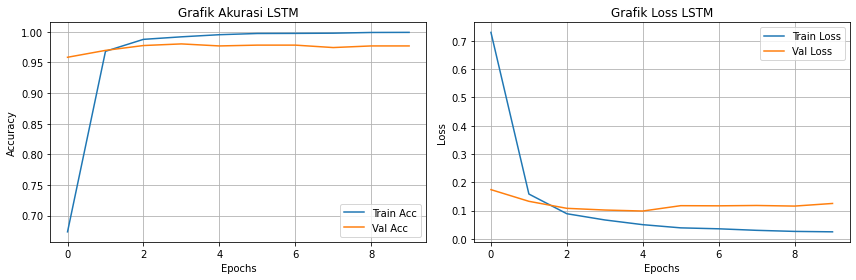

In [ ]:
# --- VISUALISASI GRAFIK AKURASI & LOSS ---
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(12, 4))

# Grafik Akurasi
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Acc')
plt.plot(val_acc, label='Val Acc')
plt.title('Grafik Akurasi LSTM')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Grafik Loss
plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.title('Grafik Loss LSTM')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Evaluasi & Confusion Matrix


Evaluasi Model Terbaik...


48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

      Normal       0.98      0.97      0.97       525
    Moderate       0.97      0.98      0.97       480
      Severe       0.99      1.00      0.99       509

    accuracy                           0.98      1514
   macro avg       0.98      0.98      0.98      1514
weighted avg       0.98      0.98      0.98      1514



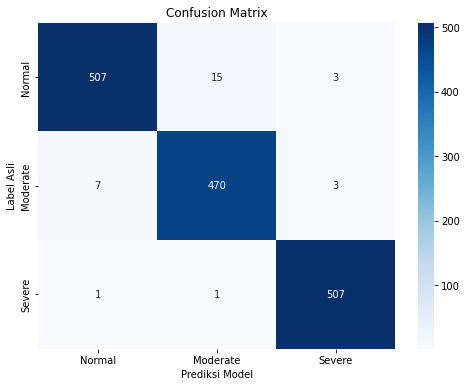

In [ ]:
print("\nEvaluasi Model Terbaik...")
# Load model terbaik yang disimpan checkpoint
best_model = tf.keras.models.load_model(os.path.join(MODEL_DIR, 'depression_model_multiclass.h5'))
    
y_pred = best_model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

# Classification Report
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred_classes, target_names=['Normal', 'Moderate', 'Severe']))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal', 'Moderate', 'Severe'], 
            yticklabels=['Normal', 'Moderate', 'Severe'])
plt.title('Confusion Matrix')
plt.ylabel('Label Asli')
plt.xlabel('Prediksi Model')
plt.show()

# Perbandingan Model Lengkap (Baseline + Ablation LSTM)

Bagian ini menggabungkan **baseline TF-IDF klasik** dan **ablation study** arsitektur LSTM:
- Baseline: TF-IDF + MultinomialNB, TF-IDF + Logistic (SGDClassifier), TF-IDF + LinearSVC  
- Ablation: **TFIDF-LSTM (Single LSTM)** vs **TFIDF-LSTM (Stacked LSTM)**

**Fairness**:
- Menggunakan **split train/test yang sama** (stratified, `random_state=42`) untuk semua metode.
- TF-IDF (untuk baseline dan untuk pemilihan vocab filter LSTM) **fit di data train saja** untuk menghindari data leakage.
- Preprocessing menggunakan teks hasil `cleaned_text`.


In [ ]:
# ==========================
# PERBANDINGAN SEMUA MODEL (FAIR SPLIT) - FINAL (SAMA DENGAN MODEL USULAN)
# Baseline TF-IDF + (NB, Logistic/SGD, LinearSVC)
# + TFIDF-LSTM Single vs Stacked (konfigurasi sama, beda hanya jumlah layer)
# ==========================

import time, random
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, f1_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.utils import class_weight

import tensorflow as tf
layers = tf.keras.layers
regularizers = tf.keras.regularizers
pad_sequences = tf.keras.preprocessing.sequence.pad_sequences

# --- Pastikan kolom tersedia ---
assert 'cleaned_text' in df.columns, "Kolom 'cleaned_text' tidak ditemukan."
assert 'label' in df.columns, "Kolom 'label' tidak ditemukan."

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# --- Samakan dengan konfigurasi model usulan ---
TFIDF_BASE_MAX_FEATURES = MAX_FEATURES   # set 4000 jika mau replikasi baseline lama
MAXLEN = MAX_LEN
EMBED_DIM = 200
EPOCHS_ABLATION = 25                     # SAMA seperti training utama
BATCH_SIZE_ABLATION = 32                 # SAMA seperti training utama

# --- Data ---
X_text_all = df['cleaned_text'].astype(str).values
y_all = df['label'].astype(int).values

# --- Split index yang sama untuk semua model ---
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(sss.split(X_text_all, y_all))

X_train_txt = X_text_all[train_idx]
X_test_txt  = X_text_all[test_idx]
y_train_lbl = y_all[train_idx]
y_test_lbl  = y_all[test_idx]

def eval_sklearn(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec_m, rec_m, f1_m, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    f1_w = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    cm = confusion_matrix(y_true, y_pred)
    return acc, prec_m, rec_m, f1_m, f1_w, cm

results = []
cms = {}

# ==========================
# (1) BASELINE TF-IDF (fit di TRAIN saja)
# ==========================
tfidf_base = TfidfVectorizer(max_features=TFIDF_BASE_MAX_FEATURES, ngram_range=(1, 1))
X_train_vec = tfidf_base.fit_transform(X_train_txt)
X_test_vec  = tfidf_base.transform(X_test_txt)

baseline_models = [
    ("TF-IDF + MultinomialNB", MultinomialNB()),
    ("TF-IDF + Logistic (SGDClassifier)", SGDClassifier(
        loss="log_loss", max_iter=2000, tol=1e-3, class_weight="balanced", random_state=RANDOM_STATE
    )),
    ("TF-IDF + LinearSVC", LinearSVC(class_weight="balanced", random_state=RANDOM_STATE))
]

for name, clf in baseline_models:
    t0 = time.time()
    clf.fit(X_train_vec, y_train_lbl)
    y_pred = clf.predict(X_test_vec)
    train_time = time.time() - t0

    acc, prec_m, rec_m, f1_m, f1_w, cm = eval_sklearn(y_test_lbl, y_pred)
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision (Macro)": prec_m,
        "Recall (Macro)": rec_m,
        "F1 (Macro)": f1_m,
        "F1 (Weighted)": f1_w,
        "TrainTime(s)": train_time
    })
    cms[name] = cm

# ==========================
# (2) TFIDF-LSTM (Single vs Stacked)
# TF-IDF vocab dibuat dari TRAIN saja, lalu teks difilter (hindari leakage)
# ==========================
train_vocab = set(tfidf_base.get_feature_names_out())

def filter_by_vocab(text, vocab_set):
    toks = text.split()
    toks = [t for t in toks if t in vocab_set]
    return " ".join(toks) if toks else "<OOV>"

X_train_f = np.array([filter_by_vocab(t, train_vocab) for t in X_train_txt], dtype=object)
X_test_f  = np.array([filter_by_vocab(t, train_vocab) for t in X_test_txt], dtype=object)

tok = tf.keras.preprocessing.text.Tokenizer(num_words=TFIDF_BASE_MAX_FEATURES, oov_token="<OOV>")
tok.fit_on_texts(X_train_f)

def to_padded(texts):
    seq = tok.texts_to_sequences(texts)
    return pad_sequences(seq, maxlen=MAXLEN, padding='post', truncating='post')

Xtr_seq = to_padded(X_train_f)
Xte_seq = to_padded(X_test_f)

ytr_oh = tf.keras.utils.to_categorical(y_train_lbl, num_classes=3)
yte_oh = tf.keras.utils.to_categorical(y_test_lbl, num_classes=3)

VOCAB_SIZE = min(TFIDF_BASE_MAX_FEATURES, len(tok.word_index) + 1)

# --- class_weight SAMA seperti training utama ---
cw = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_lbl),
    y=y_train_lbl
)
class_weight_dict = {i: w for i, w in enumerate(cw)}
print("Class weight:", class_weight_dict)

def build_lstm_model(stacked: bool):
    tf.keras.backend.clear_session()

    m = tf.keras.Sequential()
    m.add(layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM, input_length=MAXLEN))
    m.add(layers.SpatialDropout1D(0.3))

    # LSTM 1 (selalu ada)
    m.add(layers.LSTM(128, return_sequences=True, dropout=0.2, recurrent_dropout=0.2))

    # LSTM 2 (hanya untuk stacked)
    if stacked:
        m.add(layers.LSTM(64, return_sequences=True, dropout=0.2, recurrent_dropout=0.2))

    m.add(layers.GlobalMaxPooling1D())
    m.add(layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(0.001)))
    m.add(layers.Dropout(0.5))
    m.add(layers.Dense(3, activation='softmax'))

    optimizer = tf.keras.optimizers.Adam(learning_rate=0.0005, clipnorm=1.0)
    m.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
    return m

def eval_keras(model):
    probs = model.predict(Xte_seq, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    y_true = np.argmax(yte_oh, axis=1)
    return eval_sklearn(y_true, y_pred)

# --- callbacks SAMA seperti training utama ---
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

# ==========================
# Single LSTM (1 layer)
# ==========================
name_single = "TFIDF-LSTM (Single LSTM)"
single_model = build_lstm_model(stacked=False)

t0 = time.time()
single_model.fit(
    Xtr_seq, ytr_oh,
    epochs=EPOCHS_ABLATION,
    batch_size=BATCH_SIZE_ABLATION,
    validation_data=(Xte_seq, yte_oh),         # SAMA seperti training utama kamu
    callbacks=[early_stop, reduce_lr],
    class_weight=class_weight_dict,
    verbose=1
)
train_time = time.time() - t0

acc, prec_m, rec_m, f1_m, f1_w, cm = eval_keras(single_model)
results.append({
    "Model": name_single,
    "Accuracy": acc,
    "Precision (Macro)": prec_m,
    "Recall (Macro)": rec_m,
    "F1 (Macro)": f1_m,
    "F1 (Weighted)": f1_w,
    "TrainTime(s)": train_time
})
cms[name_single] = cm

# ==========================
# Stacked LSTM (2 layer) - Model Usulan
# ==========================
name_stacked = "TFIDF-LSTM (Stacked LSTM)"
stacked_model = build_lstm_model(stacked=True)

t0 = time.time()
stacked_model.fit(
    Xtr_seq, ytr_oh,
    epochs=EPOCHS_ABLATION,
    batch_size=BATCH_SIZE_ABLATION,
    validation_data=(Xte_seq, yte_oh),         # SAMA seperti training utama kamu
    callbacks=[early_stop, reduce_lr],
    class_weight=class_weight_dict,
    verbose=1
)
train_time = time.time() - t0

acc, prec_m, rec_m, f1_m, f1_w, cm = eval_keras(stacked_model)
results.append({
    "Model": name_stacked,
    "Accuracy": acc,
    "Precision (Macro)": prec_m,
    "Recall (Macro)": rec_m,
    "F1 (Macro)": f1_m,
    "F1 (Weighted)": f1_w,
    "TrainTime(s)": train_time
})
cms[name_stacked] = cm

# ==========================
# OUTPUT
# ==========================
df_compare_all = pd.DataFrame(results).sort_values(by="F1 (Macro)", ascending=False).reset_index(drop=True)
display(df_compare_all)

print("\n=== Confusion Matrix (0=Normal, 1=Moderate, 2=Severe) ===")
for name, cm in cms.items():
    print(f"\n--- {name} ---")
    display(pd.DataFrame(cm, index=["True_0","True_1","True_2"], columns=["Pred_0","Pred_1","Pred_2"]))


Class weight: {0: np.float64(0.9623271340009537), 1: np.float64(1.0510416666666667), 2: np.float64(0.990672557682867)}
Epoch 1/25


c:\Users\mjova\anaconda3\envs\skripsi\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


190/190 ━━━━━━━━━━━━━━━━━━━━ 24s 105ms/step - accuracy: 0.7456 - loss: 0.7105 - val_accuracy: 0.9610 - val_loss: 0.1770 - learning_rate: 5.0000e-04
Epoch 2/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 19s 99ms/step - accuracy: 0.9792 - loss: 0.1327 - val_accuracy: 0.9848 - val_loss: 0.0974 - learning_rate: 5.0000e-04
Epoch 3/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 19s 101ms/step - accuracy: 0.9906 - loss: 0.0770 - val_accuracy: 0.9802 - val_loss: 0.0910 - learning_rate: 5.0000e-04
Epoch 4/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 19s 101ms/step - accuracy: 0.9929 - loss: 0.0632 - val_accuracy: 0.9808 - val_loss: 0.0885 - learning_rate: 5.0000e-04
Epoch 5/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 20s 103ms/step - accuracy: 0.9959 - loss: 0.0464 - val_accuracy: 0.9861 - val_loss: 0.0876 - learning_rate: 5.0000e-04
Epoch 6/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 20s 100ms/step - accuracy: 0.9957 - loss: 0.0402 - val_accuracy: 0.9789 - val_loss: 0.0821 - learning_rate: 5.0000e-04
Epoch 7/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 19s 100ms/step - a

c:\Users\mjova\anaconda3\envs\skripsi\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


190/190 ━━━━━━━━━━━━━━━━━━━━ 43s 194ms/step - accuracy: 0.6394 - loss: 0.8247 - val_accuracy: 0.9399 - val_loss: 0.2547 - learning_rate: 5.0000e-04
Epoch 2/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 40s 211ms/step - accuracy: 0.9594 - loss: 0.2000 - val_accuracy: 0.9696 - val_loss: 0.1404 - learning_rate: 5.0000e-04
Epoch 3/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.9835 - loss: 0.1164
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00010000000474974513.
190/190 ━━━━━━━━━━━━━━━━━━━━ 36s 187ms/step - accuracy: 0.9856 - loss: 0.1028 - val_accuracy: 0.9696 - val_loss: 0.1314 - learning_rate: 5.0000e-04
Epoch 4/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 36s 192ms/step - accuracy: 0.9912 - loss: 0.0743 - val_accuracy: 0.9808 - val_loss: 0.1070 - learning_rate: 1.0000e-04
Epoch 5/25
190/190 ━━━━━━━━━━━━━━━━━━━━ 36s 191ms/step - accuracy: 0.9942 - loss: 0.0618 - val_accuracy: 0.9815 - val_loss: 0.1058 - learning_rate: 1.0000e-04


,Model,Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Weighted),TrainTime(s)
0,TFIDF-LSTM (Single LSTM),0.983487,0.983952,0.983214,0.983518,0.983500,236.216042
1,TF-IDF + LinearSVC,0.976222,0.976001,0.976468,0.976169,0.976202,0.043430
2,TF-IDF + Logistic (SGDClassifier),0.970277,0.970101,0.970793,0.970229,0.970238,0.030007
3,TFIDF-LSTM (Stacked LSTM),0.939894,0.939500,0.940177,0.939677,0.939814,191.783883
4,TF-IDF + MultinomialNB,0.892999,0.902610,0.889937,0.891250,0.891971,0.003000


... (6 outputs left out)


--- TFIDF-LSTM (Single LSTM) ---


,Pred_0,Pred_1,Pred_2
True_0,518,4,3
True_1,13,466,1
True_2,4,0,505



--- TFIDF-LSTM (Stacked LSTM) ---


,Pred_0,Pred_1,Pred_2
True_0,475,42,8
True_1,25,449,6
True_2,7,3,499


# Simpan Model

In [ ]:
model.save(os.path.join(MODEL_DIR, 'depression_model_multiclass.h5'))

# Simpan Tokenizer
with open(os.path.join(MODEL_DIR, 'tokenizer.pkl'), 'wb') as f:
    pickle.dump(tokenizer, f)

# Simpan TF-IDF
with open(os.path.join(MODEL_DIR, 'tfidf_vectorizer.pkl'), 'wb') as f:
    pickle.dump(tfidf, f)
    
print(f"Semua file tersimpan di folder '{MODEL_DIR}'")

Semua file tersimpan di folder 'c:\Users\mjova\OneDrive\Documents\kuliah\Skripsi\deteksi_depresi\models'


# Buat Bab 4

In [ ]:
df = pd.read_csv(DATASET_PATH)

# --- GENERATE TABEL UNTUK BAB 4 ---
print("\n" + "="*60)
print("   GENERATE TABEL PREPROCESSING BAB 4 (5 SAMPEL)   ")
print("="*60)
    
# Ambil 5 sampel acak (Konsisten dengan random_state)
sample_df = df.sample(5, random_state=42)[['tweet', 'class_name', 'label']].copy()
sample_df.columns = ['Raw Text', 'Class Name', 'Label']

# Fungsi Demo (Hanya untuk visualisasi langkah cleaning regex)
def demo_cleaning(text):
    text = str(text)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text) # Hapus URL
    text = re.sub(r'@\w+|#\w+', '', text)               # Hapus Mention
    text = re.sub(r'[^a-zA-Z\s]', '', text)             # Hapus Angka/Simbol
    text = re.sub(r'\s+', ' ', text).strip()            # Hapus Spasi Ganda
    return text

# Terapkan Tahapan Preprocessing
# 1. Cleaning
sample_df['Cleaning'] = sample_df['Raw Text'].apply(demo_cleaning)
    
# 2. Case Folding
sample_df['Case Folding'] = sample_df['Cleaning'].apply(str.lower)
    
# 3. Stopword Removal 
sample_df['Stopword Removal'] = sample_df['Case Folding'].apply(stopword_remover.remove)
    
# 4. Stemming 
sample_df['Stemming'] = sample_df['Stopword Removal'].apply(stemmer.stem)
    
# 5. Tokenization
sample_df['Tokenization'] = sample_df['Stemming'].apply(lambda x: str(x.split()))

# Tampilkan Tabel 
print("\n--- TABEL 4.2: HASIL CLEANING ---")
print(sample_df[['Raw Text', 'Cleaning']].to_markdown(index=False))

print("\n--- TABEL 4.3: HASIL CASE FOLDING ---")
print(sample_df[['Cleaning', 'Case Folding']].to_markdown(index=False))

print("\n--- TABEL 4.4: HASIL STOPWORD REMOVAL ---")
print(sample_df[['Case Folding', 'Stopword Removal']].to_markdown(index=False))

print("\n--- TABEL 4.5: HASIL STEMMING ---")
print(sample_df[['Stopword Removal', 'Stemming']].to_markdown(index=False))

print("\n--- TABEL 4.6: HASIL TOKENIZATION ---")
print(sample_df[['Stemming', 'Tokenization']].to_markdown(index=False))
print("\n" + "="*60)


   GENERATE TABEL PREPROCESSING BAB 4 (5 SAMPEL)   


InvalidIndexError: (['tweet'], ['class_name'], ['label'])

# Buat Lampiran

In [ ]:
df = pd.read_csv(DATASET_PATH_COMPLETE_METADATA)

# --- GENERATE TABEL HASIL AKHIR PREPROCESSING ---
print("\n" + "="*60)
print("   HASIL AKHIR PREPROCESSING (5 SAMPEL)   ")
print("="*60)
    
# Ambil 5 sampel acak (tweet dan label)
sample_df = df.sample(20, random_state=80)[['tweet', 'label', 'class_name']].copy()

# Fungsi preprocessing lengkap
def preprocess_text(text):
    text = str(text)
    # 1. Cleaning
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)  # Hapus URL
    text = re.sub(r'@\w+|#\w+', '', text)                # Hapus Mention & Hashtag
    text = re.sub(r'[^a-zA-Z\s]', '', text)              # Hapus Angka/Simbol
    text = re.sub(r'\s+', ' ', text).strip()             # Hapus Spasi Ganda
    
    # 2. Case Folding
    text = text.lower()
    
    # 3. Stopword Removal
    text = stopword_remover.remove(text)
    
    # 4. Stemming
    text = stemmer.stem(text)
    
    return text

# Terapkan preprocessing pada tweet
sample_df['Processed Tweet'] = sample_df['tweet'].apply(preprocess_text)

# Tampilkan tabel hasil akhir
print("\n--- TABEL HASIL PREPROCESSING ---")
print(sample_df[['Processed Tweet', 'label', 'class_name']].to_markdown(index=False))
print("\n" + "="*60)


   HASIL AKHIR PREPROCESSING (5 SAMPEL)   

--- TABEL HASIL PREPROCESSING ---
| Processed Tweet                                                                                                                                                                                                                  |   label | class_name   |
|:---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|--------:|:-------------|
| masih sedih anak bodoh kelas tapi kaget si nyata kating ngerjain quiz masih ada pakai gpt anak sma aku kira kampus bagus kaya nggak bakal ada                                                                                    |       1 | Moderate     |
| akhir punya bapak bapak suka buat teh kopi lebih suka wedang jahe kalau pulang kerja capek mau adek pijitin                                                  